In [1]:
# CELL 1 | SETTINGS: imports, constants (grid size, step limit, seed), actions, priority letters, capacity options
import random, heapq, time, json, os
from collections import deque

SIZE         = 20      # warehouse is SIZE x SIZE
NUM_PARCELS  = 20      # parcels per warehouse (in total)
NUM_INITIAL  = 12      # parcels already on the floor at step 0; the other 8 ARRIVE later during the run
STEP_LIMIT   = 400     # episode ends after this many steps (terminal test)
MASTER_SEED  = 42      # layout i uses seed MASTER_SEED + i
NUM_LAYOUTS  = 50      # layouts used in the experiments
SHOW_EVERY   = 100     # console menu: print a map snapshot every N steps (0 = only start/end)
DETOUR       = 10      # a partly loaded robot only fetches another parcel if it is at most this many steps away
LAYOUT_FILE  = os.path.join("data", "processed", "layouts_v2.json")   # saved layouts (offline fallback)

# Actions available to a robot (IDLE = nothing to do yet, e.g. waiting for new parcels to arrive)
MOVES = {"UP": (-1, 0), "DOWN": (1, 0), "LEFT": (0, -1), "RIGHT": (0, 1)}
ACTIONS = list(MOVES) + ["WAIT", "IDLE", "PICK", "DROP"]

# Parcel priority: the parcel value 1 / 2 / 3 is its priority Low / Medium / High (also its score)
PRIORITY = {1: "L", 2: "M", 3: "H"}

# Robot carrying capacity options (robot 1, 2, 3)
CAPACITY_SETS   = {1: [1, 1, 1], 2: [2, 2, 2], 3: [1, 2, 2]}
CAPACITY_LABELS = ["1 parcel each", "2 parcels each", "Mixed (1, 2, 2)"]

In [2]:
# CELL 2 | ENVIRONMENT: seeded layout generator, Parcel (priority + arrival time), Warehouse (grid, actions, one time step)
def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def generate_layout(seed):
    """Seeded layout generator -> plain dict (JSON friendly)."""
    rng = random.Random(seed)
    shelves = set()
    for r0 in (2, 6, 10, 14):                 # shelf block rows (2 cells tall)
        for c0 in (2, 8, 14):                 # shelf block columns (4 cells wide)
            if rng.random() < 0.9:            # seeded variation between layouts
                shelves |= {(r, c) for r in (r0, r0 + 1) for c in range(c0, c0 + 4)}
    drops  = [(0, c) for c in sorted(rng.sample(range(SIZE), 3))]
    starts = [(SIZE - 1, c) for c in rng.sample(range(SIZE), 3)]
    # parcel cells: free cell next to a shelf (robot picks from the shelf bay)
    cands = sorted((r, c) for r in range(SIZE) for c in range(SIZE)
                   if (r, c) not in shelves and (r, c) not in drops and (r, c) not in starts
                   and any((r + dr, c + dc) in shelves for dr, dc in MOVES.values()))
    spots = rng.sample(cands, min(NUM_PARCELS, len(cands)))
    # arrival step: the first NUM_INITIAL parcels are there at step 0, the rest arrive between steps 10 and 200
    arrivals = ([0] * NUM_INITIAL + [rng.randint(10, 200) for _ in range(NUM_PARCELS - NUM_INITIAL)])[:len(spots)]
    parcels = [[r, c, rng.randint(1, 3), a] for (r, c), a in zip(spots, arrivals)]   # [row, col, priority 1-3, arrival]
    return {"shelves": sorted(map(list, shelves)), "drops": list(map(list, drops)),
            "starts": list(map(list, starts)), "parcels": parcels}

_LAYOUTS = {}
def ensure_layouts():
    """Load layouts from disk, or generate the NUM_LAYOUTS seeded layouts and save them."""
    global _LAYOUTS
    if os.path.exists(LAYOUT_FILE):
        _LAYOUTS = json.load(open(LAYOUT_FILE))
    if len(_LAYOUTS) < NUM_LAYOUTS:
        _LAYOUTS = {str(MASTER_SEED + i): generate_layout(MASTER_SEED + i) for i in range(NUM_LAYOUTS)}
        os.makedirs(os.path.dirname(LAYOUT_FILE), exist_ok=True)
        json.dump(_LAYOUTS, open(LAYOUT_FILE, "w"))

def get_layout(seed):
    ensure_layouts()
    return _LAYOUTS.get(str(seed)) or generate_layout(seed)

class Parcel:
    def __init__(self, pid, cell, value, arrival=0):
        self.id, self.cell, self.value, self.arrival = pid, cell, value, arrival
        self.status = "waiting" if arrival == 0 else "pending"   # pending (not arrived yet) / waiting / carried / delivered
    @property
    def priority(self):                       # "L", "M" or "H"
        return PRIORITY[self.value]

class Warehouse:
    """The environment: grid, shelves, parcels, drop-offs, robots, time_step."""
    def __init__(self, seed):
        lay = get_layout(seed)
        self.grid = [["." for _ in range(SIZE)] for _ in range(SIZE)]   # "." aisle, "#" shelf
        for r, c in lay["shelves"]: self.grid[r][c] = "#"
        self.drops  = [tuple(d) for d in lay["drops"]]
        self.starts = [tuple(s) for s in lay["starts"]]
        self.parcels = [Parcel(i, (r, c), v, a) for i, (r, c, v, a) in enumerate(lay["parcels"])]
        self.claims = {}                      # parcel id -> robot id (stops two robots chasing one parcel)
        self.robots = []                      # filled by run_episode / Sim
        self.new_arrivals = []                # parcels that arrived in the latest step (GUI shows "just arrived")
        self.time_step = 0

    def is_free(self, cell):                  # inside grid and not a shelf
        r, c = cell
        return 0 <= r < SIZE and 0 <= c < SIZE and self.grid[r][c] != "#"

    def neighbors(self, cell):
        return free_neighbors(self.grid, cell)

    def robot_at(self, cell):
        return next((r for r in self.robots if r.cell == cell), None)

    def waiting_parcel_at(self, cell):
        return next((p for p in self.parcels if p.status == "waiting" and p.cell == cell), None)

    def percept(self, robot):
        """What a robot is allowed to sense. Parcels that have not arrived yet are NOT visible."""
        return {"id": robot.id, "cell": robot.cell, "cargo": robot.cargo, "capacity": robot.capacity,
                "grid": self.grid, "parcels": [p for p in self.parcels if p.status == "waiting"],
                "drops": self.drops, "others": {r.cell for r in self.robots if r is not robot},
                "claims": self.claims}

    def apply(self, robot, action):
        """Execute one action. Illegal moves (shelf / off grid / another robot) are not allowed -> robot waits."""
        if action in MOVES:
            dr, dc = MOVES[action]
            new = (robot.cell[0] + dr, robot.cell[1] + dc)
            if self.is_free(new) and self.robot_at(new) is None:
                robot.cell = new; robot.distance_travelled += 1
            else:
                robot.wait_steps += 1
        elif action == "PICK":                # pick up ONE parcel, if there is room in the cargo
            p = self.waiting_parcel_at(robot.cell)
            if p and len(robot.cargo) < robot.capacity and self.claims.get(p.id, robot.id) == robot.id:
                p.status = "carried"; robot.cargo.append(p); self.claims.pop(p.id, None)
            else:
                robot.wait_steps += 1
        elif action == "DROP":                # deliver EVERYTHING the robot carries
            if robot.cargo and robot.cell in self.drops:
                for p in robot.cargo:
                    p.status = "delivered"; robot.deliveries += 1; robot.score += p.value
                robot.cargo = []
            else:
                robot.wait_steps += 1
        elif action == "IDLE":                # nothing to do (not counted as a blocked wait)
            robot.idle_steps += 1
        else:                                  # WAIT
            robot.wait_steps += 1

    def step(self):
        """One time step: new parcels appear, then robots act one after another (so no collisions)."""
        self.new_arrivals = [p for p in self.parcels if p.status == "pending" and p.arrival <= self.time_step]
        for p in self.new_arrivals: p.status = "waiting"
        n = len(self.robots); k = self.time_step % n
        for robot in self.robots[k:] + self.robots[:k]:
            self.apply(robot, robot.choose_action(self.percept(robot)))
        self.time_step += 1

    def done(self):                            # terminal test: all delivered or step limit
        return all(p.status == "delivered" for p in self.parcels) or self.time_step >= STEP_LIMIT

    def render_text(self):
        """# shelf, . aisle, D drop-off, P parcel, 1/2/3 robot, a/b/c robot carrying parcel(s)."""
        rows = []
        for r in range(SIZE):
            line = ""
            for c in range(SIZE):
                ch = "D" if (r, c) in self.drops else self.grid[r][c]
                if self.waiting_parcel_at((r, c)): ch = "P"
                rb = self.robot_at((r, c))
                if rb: ch = str(rb.id) if not rb.cargo else "abc"[rb.id - 1]
                line += ch
            rows.append(line)
        return "\n".join(rows)

def free_neighbors(grid, cell):
    r, c = cell
    return [n for n in ((r-1, c), (r+1, c), (r, c-1), (r, c+1))
            if 0 <= n[0] < SIZE and 0 <= n[1] < SIZE and grid[n[0]][n[1]] != "#"]

In [3]:
# CELL 3 | PLANNERS: BFS, A*, Dijkstra, Greedy Best-First, DFS (each returns path, cost, nodes expanded)
def build_path(parent, cur):
    path = []
    while cur is not None:
        path.append(cur); cur = parent[cur]
    return path[::-1]

class Planner:
    """Abstract planner. plan() wraps _search() to count nodes, calls and run time."""
    name = "Planner"
    def __init__(self):
        self.nodes_total = 0; self.calls = 0; self.time_total = 0.0
    def plan(self, grid, start, goal, blocked=frozenset()):
        t = time.perf_counter()
        path, nodes = self._search(grid, start, goal, blocked)
        self.time_total += time.perf_counter() - t
        self.nodes_total += nodes; self.calls += 1
        return path, (len(path) - 1 if path else None), nodes      # (path, cost, nodes_expanded)
    def _search(self, grid, start, goal, blocked):
        raise NotImplementedError

class BFSPlanner(Planner):
    """Uninformed, optimal: FIFO queue, expands cells layer by layer."""
    name = "BFS"
    def _search(self, grid, start, goal, blocked):
        frontier, parent, nodes = deque([start]), {start: None}, 0   # parent doubles as explored set
        while frontier:
            cur = frontier.popleft(); nodes += 1
            if cur == goal: return build_path(parent, cur), nodes
            for n in free_neighbors(grid, cur):
                if n not in parent and (n not in blocked or n == goal):
                    parent[n] = cur; frontier.append(n)
        return None, nodes

class AStarPlanner(Planner):
    """Informed, optimal: f = g + h with Manhattan heuristic (admissible), so fewer nodes than BFS."""
    name = "A*"
    def _search(self, grid, start, goal, blocked):
        h = lambda p: manhattan(p, goal)
        heap, g_cost, parent, closed, nodes = [(h(start), 0, start)], {start: 0}, {start: None}, set(), 0
        while heap:
            f, g, cur = heapq.heappop(heap)
            if cur in closed: continue
            closed.add(cur); nodes += 1
            if cur == goal: return build_path(parent, cur), nodes
            for n in free_neighbors(grid, cur):
                if n in blocked and n != goal: continue
                if g + 1 < g_cost.get(n, 10**9):
                    g_cost[n] = g + 1; parent[n] = cur
                    heapq.heappush(heap, (g + 1 + h(n), g + 1, n))
        return None, nodes

class DijkstraPlanner(Planner):
    """Uninformed, optimal: expands the cheapest cell first (g only). With equal step costs it behaves like BFS."""
    name = "Dijkstra"
    def _search(self, grid, start, goal, blocked):
        heap, dist, parent, closed, nodes = [(0, start)], {start: 0}, {start: None}, set(), 0
        while heap:
            g, cur = heapq.heappop(heap)
            if cur in closed: continue
            closed.add(cur); nodes += 1
            if cur == goal: return build_path(parent, cur), nodes
            for n in free_neighbors(grid, cur):
                if n in blocked and n != goal: continue
                if g + 1 < dist.get(n, 10**9):
                    dist[n] = g + 1; parent[n] = cur
                    heapq.heappush(heap, (g + 1, n))
        return None, nodes

class GreedyPlanner(Planner):
    """Informed, NOT optimal: always expands the cell with the smallest h (Manhattan distance to goal), ignores g."""
    name = "Greedy"
    def _search(self, grid, start, goal, blocked):
        h = lambda p: manhattan(p, goal)
        heap, parent, nodes = [(h(start), start, None)], {}, 0   # heap entry = (h, cell, cell we came from)
        while heap:
            _, cur, par = heapq.heappop(heap)
            if cur in parent: continue                          # already expanded
            parent[cur] = par; nodes += 1
            if cur == goal: return build_path(parent, cur), nodes
            for n in free_neighbors(grid, cur):
                if n not in parent and (n not in blocked or n == goal):
                    heapq.heappush(heap, (h(n), n, cur))
        return None, nodes

class DFSPlanner(Planner):
    """Uninformed, NOT optimal: LIFO stack, goes as deep as possible first, so paths are long and winding."""
    name = "DFS"
    def _search(self, grid, start, goal, blocked):
        stack, parent, nodes = [(start, None)], {}, 0           # stack entry = (cell, cell we came from)
        while stack:
            cur, par = stack.pop()
            if cur in parent: continue                          # already expanded
            parent[cur] = par; nodes += 1
            if cur == goal: return build_path(parent, cur), nodes
            for n in reversed(free_neighbors(grid, cur)):       # reversed so UP is explored first
                if n not in parent and (n not in blocked or n == goal):
                    stack.append((n, cur))
        return None, nodes

PLANNERS = {"BFS": BFSPlanner, "A*": AStarPlanner, "Dijkstra": DijkstraPlanner,
            "Greedy": GreedyPlanner, "DFS": DFSPlanner}
ALGO_KEYS   = list(PLANNERS)                                               # algorithms in menu order
ALGO_LABELS = ["BFS", "A*", "Dijkstra", "Greedy Best-First", "DFS", "Compare All"]

In [4]:
# CELL 4 | ROBOTS: Random, Simple Reflex, Goal-Based, Utility-Based (with carrying capacity)
def direction(a, b):
    """Action name that moves from cell a to adjacent cell b."""
    d = (b[0] - a[0], b[1] - a[1])
    return next(k for k, v in MOVES.items() if v == d)

class Robot:
    """Abstract robot: state + metrics. Subclasses implement choose_action(percept)."""
    def __init__(self, rid, cell, planner=None, seed=0, capacity=1):
        self.id, self.cell, self.planner = rid, cell, planner
        self.capacity = capacity; self.cargo = []         # parcels currently carried (at most `capacity`)
        self.distance_travelled = 0; self.wait_steps = 0; self.idle_steps = 0
        self.deliveries = 0; self.score = 0
        self.rng = random.Random(seed * 100 + rid)        # own RNG => reproducible randomness
    def full(self):
        return len(self.cargo) >= self.capacity
    def choose_action(self, percept):
        raise NotImplementedError
    def random_step(self, p):
        opts = [n for n in free_neighbors(p["grid"], p["cell"]) if n not in p["others"]]
        return direction(p["cell"], self.rng.choice(opts)) if opts else "WAIT"
    def on_parcel(self, p):                              # a waiting parcel is under the robot
        return any(x.cell == p["cell"] for x in p["parcels"])


class RandomRobot(Robot):
    """Baseline: random walk, picks/drops only when standing on a parcel / drop-off."""
    def choose_action(self, p):
        if not self.full() and self.on_parcel(p): return "PICK"
        if self.cargo and p["cell"] in p["drops"]: return "DROP"
        return self.random_step(p)


class ReflexRobot(Robot):
    """Simple reflex: rules over the current cell and the FOUR neighbouring cells only."""
    def choose_action(self, p):
        cell = p["cell"]
        if not self.full() and self.on_parcel(p): return "PICK"                  # rule 1
        if self.cargo and cell in p["drops"]: return "DROP"                      # rule 2
        free = [n for n in free_neighbors(p["grid"], cell) if n not in p["others"]]
        if not self.full():                                                      # rule 3: parcel next to me
            for n in free:
                if any(x.cell == n for x in p["parcels"]): return direction(cell, n)
        if self.cargo:
            for n in free:                                                       # rule 4: drop-off next to me
                if n in p["drops"]: return direction(cell, n)
            up = (cell[0] - 1, cell[1])                                          # rule 5: carrying -> head UP
            if up in free: return "UP"                                           #   (drop-offs are on the top row)
        return self.random_step(p)                                               # rule 6: wander


class GoalBasedRobot(Robot):
    """Goal-based: plans a full path with a Planner and follows it; capacity 2 = may fetch a 2nd parcel nearby."""
    def __init__(self, rid, cell, planner=None, seed=0, capacity=1):
        super().__init__(rid, cell, planner, seed, capacity)
        self.target = None; self.path = None; self.blocked = 0; self.delivering = False

    def choose_target(self, p, limit=None):
        """Goal-based rule: NEAREST unclaimed parcel by path cost (optionally within `limit` steps)."""
        best, best_path, best_cost = None, None, 10**9
        for parcel in p["parcels"]:
            if parcel.id in p["claims"]: continue
            path, cost, _ = self.planner.plan(p["grid"], p["cell"], parcel.cell)
            if path and (limit is None or cost <= limit) and cost < best_cost:
                best, best_path, best_cost = parcel, path, cost
        return best, best_path

    def path_to_nearest_drop(self, p, blocked=frozenset()):
        best = None
        for d in p["drops"]:
            path, cost, _ = self.planner.plan(p["grid"], p["cell"], d, blocked)
            if path and (best is None or cost < len(best) - 1): best = path
        return best

    def goal_path(self, p, avoid):
        blocked = frozenset(p["others"]) if avoid else frozenset()
        if self.target is not None:
            return self.planner.plan(p["grid"], p["cell"], self.target.cell, blocked)[0]
        return self.path_to_nearest_drop(p, blocked)

    def choose_action(self, p):
        cell = p["cell"]
        if self.target and self.target.status != "waiting":      # picked it (or lost it) -> forget the target
            self.target, self.path = None, None
        if self.cargo and cell in p["drops"]:                    # at a drop-off with cargo -> deliver all
            self.path, self.delivering = None, False
            return "DROP"
        if self.target is None and not self.full() and not self.delivering:
            limit = DETOUR if self.cargo else None               # partly loaded: only a small detour is allowed
            self.target, self.path = self.choose_target(p, limit)
            if self.target: p["claims"][self.target.id] = self.id   # reserve the parcel
            elif self.cargo: self.delivering = True                 # nothing close -> go and deliver
        if self.target is not None:                              # goal: fetch a parcel
            if cell == self.target.cell: return "PICK"
        elif self.cargo:                                         # goal: deliver
            if not self.path or self.path[-1] not in p["drops"]:
                self.path = self.path_to_nearest_drop(p)
        else:                                                    # nothing to do yet (new parcels may still arrive)
            self.path = None
            if cell in p["drops"] or self.on_parcel(p):          # don't block a drop-off or a claimed parcel cell
                return self.random_step(p)
            return "IDLE"
        return self.follow_path(p)

    def follow_path(self, p):
        cell = p["cell"]
        if not self.path or self.path[0] != cell:              # no plan / out of sync -> re-plan
            self.path = self.goal_path(p, False)
        if not self.path or len(self.path) < 2: return "WAIT"
        nxt = self.path[1]
        if nxt in p["others"]:                                 # another robot is in the way
            self.blocked += 1
            if self.blocked < 2: return "WAIT"                 # wait first ...
            self.blocked = 0
            alt = self.goal_path(p, True)                      # ... then re-plan around other robots
            if alt and len(alt) > 1 and alt[1] not in p["others"]:
                self.path, nxt = alt, alt[1]
            else:
                self.path = None; return self.random_step(p)   # no way round -> sidestep
        else:
            self.blocked = 0
        self.path.pop(0)
        return direction(cell, nxt)


class UtilityBasedRobot(GoalBasedRobot):
    """Utility-based: like goal-based, but picks the parcel with the highest utility (priority counts)."""
    def choose_target(self, p, limit=None):
        # U = 10 * priority value - (distance to parcel + distance to drop-off)
        best, best_path, best_u = None, None, -10**9
        for parcel in p["parcels"]:
            if parcel.id in p["claims"]: continue
            path, cost, _ = self.planner.plan(p["grid"], p["cell"], parcel.cell)
            if not path or (limit is not None and cost > limit): continue
            to_drop = min(manhattan(parcel.cell, d) for d in p["drops"])   # cheap estimate of parcel->drop
            u = 10 * parcel.value - (cost + to_drop)
            if u > best_u: best, best_path, best_u = parcel, path, u
        return best, best_path

ROBOT_TYPES = {1: ReflexRobot, 2: GoalBasedRobot, 3: UtilityBasedRobot}

In [5]:
# CELL 5 | EXPERIMENT CODE: run_episode, reports, planner comparison, run_all (50 layouts)
def run_episode(robot_cls, planner_cls, seed, n_robots=2, verbose=False, capacities=None):
    caps = capacities or [1] * n_robots
    world = Warehouse(seed)
    planner = planner_cls()
    world.robots = [robot_cls(i + 1, world.starts[i], planner, seed, caps[i]) for i in range(n_robots)]
    if verbose:
        print(f"\n=== {robot_cls.__name__} | {planner.name} | {n_robots} robot(s), capacities {caps[:n_robots]} | layout seed {seed} ===")
        print("Legend: # shelf, D drop-off, P parcel, 1/2/3 robot, a/b/c robot carrying parcel(s). Parcels arrive during the run.")
        print(f"\nStep 0\n{world.render_text()}")
    while not world.done():
        world.step()
        if verbose and SHOW_EVERY and world.time_step % SHOW_EVERY == 0 and not world.done():
            print(f"\nStep {world.time_step}\n{world.render_text()}")
    if verbose: print(f"\nFinal map (step {world.time_step})\n{world.render_text()}")
    return {
        "robot": robot_cls.__name__, "planner": planner.name, "seed": seed, "n_robots": n_robots,
        "capacities": caps[:n_robots],
        "finished": all(p.status == "delivered" for p in world.parcels), "steps": world.time_step,
        "delivered": sum(r.deliveries for r in world.robots), "total": len(world.parcels),
        "score": sum(r.score for r in world.robots),
        "distance": sum(r.distance_travelled for r in world.robots),
        "waits": sum(r.wait_steps for r in world.robots), "idle": sum(r.idle_steps for r in world.robots),
        "nodes": planner.nodes_total, "plan_time": planner.time_total,
        "per_robot": [(r.id, r.deliveries, r.distance_travelled, r.capacity) for r in world.robots],
    }

def print_report(m):
    print("\n--------- PERFORMANCE REPORT ---------")
    print(f"Robot type: {m['robot']} | Planner: {m['planner']} | Robots: {m['n_robots']} | Capacities: {m['capacities']}")
    print(f"Parcels delivered     : {m['delivered']} / {m['total']}  ({'all done' if m['finished'] else 'step limit reached'})")
    print(f"Weighted score        : {m['score']}  (L=1, M=2, H=3 per delivered parcel)")
    print(f"Steps used            : {m['steps']} / {STEP_LIMIT}")
    print(f"Distance travelled    : {m['distance']} moves | waiting steps: {m['waits']} | idle steps: {m['idle']}")
    print(f"Nodes expanded        : {m['nodes']} | planning time: {m['plan_time']*1000:.1f} ms")
    for rid, d, dist, cap in m["per_robot"]:
        print(f"   Robot {rid} (carries up to {cap}): {d} deliveries, {dist} moves")

def compare_report(results):
    r = results[0]
    print("\n=========== ALGORITHM COMPARISON (same layout) ===========")
    print(f"{r['robot']} | {r['n_robots']} robot(s) | capacities {r['capacities']} | layout seed {r['seed']}")
    print(f"{'Metric':<22}" + "".join(f"{m['planner']:>10}" for m in results))
    for label, key in [("Parcels delivered", "delivered"), ("Weighted score", "score"), ("Steps used", "steps"),
                       ("Distance travelled", "distance"), ("Waiting steps", "waits"), ("Nodes expanded", "nodes")]:
        print(f"{label:<22}" + "".join(f"{m[key]:>10}" for m in results))
    print(f"{'Planning time (ms)':<22}" + "".join(f"{m['plan_time']*1000:>10.1f}" for m in results))

def mean(xs): return sum(xs) / len(xs) if xs else 0

def table(headers, rows):
    w = [max(len(str(x)) for x in col) + 2 for col in zip(headers, *rows)]
    print("".join(str(h).ljust(wi) for h, wi in zip(headers, w)))
    print("-" * sum(w))
    for r in rows: print("".join(str(x).ljust(wi) for x, wi in zip(r, w)))

def planner_comparison(seeds):
    """All planners on every layout: start->parcel and parcel->each drop-off queries."""
    stats = {n: {"nodes": [], "cost": [], "time": 0.0, "per_layout": [], "optimal": 0} for n in PLANNERS}
    queries_total = 0
    for s in seeds:
        w = Warehouse(s)
        queries = [(st, p.cell) for st in w.starts for p in w.parcels] + \
                  [(p.cell, d) for p in w.parcels for d in w.drops]
        start_idx = {n: len(stats[n]["nodes"]) for n in PLANNERS}
        for a, b in queries:
            costs = {}
            for n, cls in PLANNERS.items():
                pl = cls(); path, cost, nodes = pl.plan(w.grid, a, b)
                stats[n]["nodes"].append(nodes); stats[n]["cost"].append(cost); stats[n]["time"] += pl.time_total
                costs[n] = cost
            for n in PLANNERS: stats[n]["optimal"] += (costs[n] == costs["BFS"])
            queries_total += 1
        for n in PLANNERS:                                   # average nodes on THIS layout (chart 1)
            stats[n]["per_layout"].append(mean(stats[n]["nodes"][start_idx[n]:]))
    return stats, queries_total

def run_all(n_layouts=NUM_LAYOUTS):
    ensure_layouts()
    seeds = [MASTER_SEED + i for i in range(n_layouts)]
    results = {}
    # (a) all planners
    stats, nq = planner_comparison(seeds)
    print(f"\n(a) PLANNERS on {n_layouts} layouts ({nq} start->parcel / parcel->drop-off queries)")
    table(["Planner", "Avg nodes", "Avg path cost", "Optimal paths", "Total time (s)"],
          [[n, f"{mean(v['nodes']):.1f}", f"{mean(v['cost']):.2f}", f"{v['optimal'] / nq:.0%}", f"{v['time']:.2f}"]
           for n, v in stats.items()])
    print(f"A* expands {mean(stats['A*']['nodes']) / mean(stats['BFS']['nodes']):.0%} of the nodes BFS expands (both optimal).")
    results["planners"] = stats
    # (b) robot types, 2 robots, A*
    print(f"\n(b) ROBOT TYPES, 2 robots (capacity 1), A*, {n_layouts} layouts (averages)")
    rows, results["agents"] = [], {}
    for cls in (RandomRobot, ReflexRobot, GoalBasedRobot, UtilityBasedRobot):
        ms = [run_episode(cls, AStarPlanner, s, 2) for s in seeds]
        results["agents"][cls.__name__] = ms
        rows.append([cls.__name__, f"{mean([m['delivered'] for m in ms]):.1f}", f"{mean([m['score'] for m in ms]):.1f}",
                     f"{mean([m['distance'] for m in ms]):.0f}", f"{mean([m['waits'] for m in ms]):.0f}",
                     f"{mean([m['nodes'] for m in ms]):.0f}"])
    table(["Robot", "Delivered", "Score", "Distance", "Waits", "Nodes"], rows)
    # (c) number of robots
    print(f"\n(c) NUMBER OF ROBOTS (A*, avg parcels delivered / avg steps used)")
    rows, results["robots"] = [], {}
    for cls in (GoalBasedRobot, UtilityBasedRobot):
        row = [cls.__name__]
        for n in (1, 2, 3):
            ms = [run_episode(cls, AStarPlanner, s, n) for s in seeds]
            results["robots"][(cls.__name__, n)] = ms
            row.append(f"{mean([m['delivered'] for m in ms]):.1f} / {mean([m['steps'] for m in ms]):.0f}")
        rows.append(row)
    table(["Robot", "1 robot", "2 robots", "3 robots"], rows)
    # (d) every planner inside the simulation
    print(f"\n(d) ALL PLANNERS inside the simulation (Goal-Based, 2 robots, {n_layouts} layouts, averages)")
    rows, results["sim_planners"] = [], {}
    for name, cls in PLANNERS.items():
        ms = [run_episode(GoalBasedRobot, cls, s, 2) for s in seeds]
        results["sim_planners"][name] = ms
        rows.append([name, f"{mean([m['delivered'] for m in ms]):.1f}", f"{mean([m['steps'] for m in ms]):.0f}",
                     f"{mean([m['distance'] for m in ms]):.0f}", f"{mean([m['nodes'] for m in ms]):.0f}"])
    table(["Planner", "Delivered", "Steps", "Distance", "Nodes"], rows)
    # (e) carrying capacity
    print(f"\n(e) CARRYING CAPACITY (A*, 2 robots, {n_layouts} layouts, averages)")
    rows, results["capacity"] = [], {}
    for cls in (GoalBasedRobot, UtilityBasedRobot):
        for label, caps in (("1 + 1", [1, 1]), ("2 + 2", [2, 2]), ("1 + 2", [1, 2])):
            ms = [run_episode(cls, AStarPlanner, s, 2, capacities=caps) for s in seeds]
            results["capacity"][(cls.__name__, label)] = ms
            rows.append([cls.__name__, label, f"{mean([m['delivered'] for m in ms]):.1f}", f"{mean([m['steps'] for m in ms]):.0f}",
                         f"{mean([m['distance'] for m in ms]):.0f}"])
    table(["Robot", "Capacities", "Delivered", "Steps", "Distance"], rows)
    return results

In [6]:
# CELL 6 | SIMULATION WRAPPER + CHARTS: Sim class (records history for charts) and Matplotlib chart functions
import matplotlib.pyplot as plt

# Letters shown on the robots: S1, G2, U3 ... (keyed by class NAME, so re-running cells never breaks it)
LETTER = {"ReflexRobot": "S", "GoalBasedRobot": "G", "UtilityBasedRobot": "U", "RandomRobot": "R"}
ROBOT_NAMES = {"S": "Simple Reflex", "G": "Goal-Based", "U": "Utility-Based", "R": "Random"}

class Sim:
    """One simulation = a Warehouse + its robots. Records history so charts can be drawn when it ends."""
    def __init__(self, robot_cls, planner_cls, seed, n_robots, capacities=None):
        caps = capacities or [1] * n_robots
        self.seed = seed
        self.world = Warehouse(seed)
        self.planner = planner_cls()
        self.letter = LETTER[robot_cls.__name__]
        self.world.robots = [robot_cls(i + 1, self.world.starts[i], self.planner, seed, caps[i]) for i in range(n_robots)]
        self.prev = {r.id: r.cell for r in self.world.robots}    # previous cells (smooth GUI movement)
        self.popups = []                                         # floating "+score" texts (GUI)
        self.arrivals = []                                       # (cell, time) of newly arrived parcels ("just arrived")
        self.history = [(0, 0, 0)]                               # (step, parcels delivered, distance) after every step

    def step(self, now=0):
        w = self.world
        if w.done(): return
        self.prev = {r.id: r.cell for r in w.robots}
        before = {r.id: r.score for r in w.robots}
        w.step()                                                 # parcels arrive, then robots plan, move, pick, drop
        for p in w.new_arrivals: self.arrivals.append((p.cell, now))
        for r in w.robots:
            if r.score > before[r.id]:
                self.popups.append((r.cell, f"+{r.score - before[r.id]}", now))
        self.history.append((w.time_step, sum(r.deliveries for r in w.robots),
                             sum(r.distance_travelled for r in w.robots)))

    def metrics(self):
        w = self.world
        return {"delivered": sum(r.deliveries for r in w.robots), "score": sum(r.score for r in w.robots),
                "steps": w.time_step, "distance": sum(r.distance_travelled for r in w.robots),
                "waits": sum(r.wait_steps for r in w.robots), "idle": sum(r.idle_steps for r in w.robots),
                "nodes": self.planner.nodes_total}

    def status(self):
        w = self.world
        if not w.done(): return "Running"
        return "Finished" if all(p.status == "delivered" for p in w.parcels) else "Step limit reached"

# ----- chart theme: mint / ice-blue background, plum-purple text -----
C_BG, C_AX, C_TEXT = "#D6F2EC", "#F3FDFB", "#5B2A6E"
C_ROBOT = ["#E58FB0", "#6F9DE8", "#EDA55F"]                      # colours of robots 1, 2, 3
C_PLAN = {"BFS": "#E58FB0", "A*": "#6F9DE8", "Dijkstra": "#5FB89A", "Greedy": "#EDA55F", "DFS": "#9C7BC9"}
C_TYPE = {"RandomRobot": "#B7A8C9", "ReflexRobot": "#E58FB0", "GoalBasedRobot": "#6F9DE8", "UtilityBasedRobot": "#EDA55F"}
PRETTY = {"RandomRobot": "Random", "ReflexRobot": "Reflex", "GoalBasedRobot": "Goal-Based", "UtilityBasedRobot": "Utility-Based"}
plt.rcParams.update({"figure.facecolor": C_BG, "axes.facecolor": C_AX, "text.color": C_TEXT,
                     "axes.labelcolor": C_TEXT, "axes.edgecolor": C_TEXT, "xtick.color": C_TEXT,
                     "ytick.color": C_TEXT, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.grid": True, "grid.color": "#BFE3DB", "font.size": 10})

def std(xs):
    m = mean(xs); return (sum((x - m) ** 2 for x in xs) / len(xs)) ** 0.5 if xs else 0

def draw_sim_figure(fig, sims):
    """Fill a Matplotlib Figure with the charts of ONE finished simulation (or several planners compared)."""
    total, letter = len(sims[0].world.parcels), sims[0].letter
    axes = fig.subplots(2, 2)
    ax = axes[0][0]                                              # (1) deliveries over time
    for s in sims:
        h = s.history
        ax.step([x[0] for x in h], [x[1] for x in h], where="post", lw=2.2,
                color=C_PLAN[s.planner.name] if len(sims) > 1 else "#6F9DE8",
                label=f"{s.planner.name}: {h[-1][1]}/{total} in {h[-1][0]} steps")
    ax.set_xlabel("Step"); ax.set_ylabel("Parcels delivered"); ax.set_title("Deliveries over time")
    ax.legend(loc="lower right", fontsize=7)
    if len(sims) == 1:                                           # single run: one bar per robot
        rs = sims[0].world.robots
        names, cols = [f"{letter}{r.id} (x{r.capacity})" for r in rs], C_ROBOT[:len(rs)]
        panels = [(axes[0][1], [r.deliveries for r in rs], "Parcels delivered per robot"),
                  (axes[1][0], [r.distance_travelled for r in rs], "Distance travelled per robot (moves)"),
                  (axes[1][1], [r.wait_steps for r in rs], "Waiting steps per robot")]
        algo = "no planning" if letter == "S" else sims[0].planner.name
    else:                                                        # compare: one bar per planner
        names = [s.planner.name for s in sims]; cols = [C_PLAN[n] for n in names]
        m = [s.metrics() for s in sims]
        panels = [(axes[0][1], [x["nodes"] for x in m], "Search nodes expanded"),
                  (axes[1][0], [x["distance"] for x in m], "Total distance travelled (moves)"),
                  (axes[1][1], [x["waits"] for x in m], "Total waiting steps")]
        algo = "all algorithms compared"
    for a_, vals, title in panels:
        bars = a_.bar(names, vals, color=cols, edgecolor=C_TEXT)
        a_.bar_label(bars, color=C_TEXT, fontsize=8); a_.set_title(title); a_.margins(y=0.15)
    fig.suptitle(f"{ROBOT_NAMES[letter]} | {algo} | {len(sims[0].world.robots)} robot(s) | "
                 f"layout seed {sims[0].seed} | {sims[0].status()}", color=C_TEXT, fontweight="bold", fontsize=12)
    fig.tight_layout()
    return fig

def show_sim_charts(sims):
    """Notebook-only helper (used by simulate_and_chart). The GUI draws the same charts inside its own window."""
    fig = draw_sim_figure(plt.figure(figsize=(12, 8)), sims)
    plt.show(); plt.close(fig)

def simulate_and_chart(robot_cls, algos=("A*",), n_robots=2, capacities=None, seed=MASTER_SEED):
    """No GUI: run the simulation to the end, then show its charts. algos = e.g. ["A*"] or list(PLANNERS)."""
    sims = [Sim(robot_cls, PLANNERS[a], seed, n_robots, capacities) for a in algos]
    while not all(s.world.done() for s in sims):
        for s in sims: s.step()
    show_sim_charts(sims)
    return sims

# ----- the experiment charts from the proposal (used with run_all's RESULTS; displayed only) -----
def chart_nodes(results):
    st = results["planners"]
    fig, ax = plt.subplots(figsize=(10, 4.5))
    for n, v in st.items():
        ax.plot(range(1, len(v["per_layout"]) + 1), v["per_layout"], marker="o", ms=3, color=C_PLAN[n],
                label=f"{n} (avg {mean(v['per_layout']):.0f})")
    ax.set_xlabel("Layout number (seed 42 + i)"); ax.set_ylabel("Avg nodes expanded per query")
    ax.set_title("Chart 1: Nodes expanded per layout, all planners"); ax.legend(ncol=5, fontsize=8)
    fig.tight_layout(); return fig

def chart_delivered(results):
    names = list(results["agents"])
    data = [[m["delivered"] for m in results["agents"][n]] for n in names]
    fig, ax = plt.subplots(figsize=(8, 4.8))
    bp = ax.boxplot(data, patch_artist=True, tick_labels=[PRETTY[n] for n in names], medianprops={"color": C_TEXT, "linewidth": 2})
    for patch, n in zip(bp["boxes"], names): patch.set_facecolor(C_TYPE[n])
    for i, d in enumerate(data, 1): ax.scatter([i], [mean(d)], marker="D", color=C_TEXT, zorder=3, label="mean" if i == 1 else None)
    ax.set_ylabel(f"Parcels delivered (of {NUM_PARCELS})"); ax.set_title("Chart 2: Parcels delivered per robot type (2 robots, 400 steps)")
    ax.legend(loc="center left"); fig.tight_layout(); return fig

def chart_distance_waits(results):
    names = list(results["agents"])
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
    for ax, key, title in ((axes[0], "distance", "Total distance travelled (moves)"), (axes[1], "waits", "Waiting steps")):
        vals = [[m[key] for m in results["agents"][n]] for n in names]
        ax.bar([PRETTY[n] for n in names], [mean(v) for v in vals], yerr=[std(v) for v in vals], capsize=5,
               color=[C_TYPE[n] for n in names], edgecolor=C_TEXT, error_kw={"ecolor": C_TEXT})
        ax.set_title(title); ax.tick_params(axis="x", rotation=15)
    fig.suptitle("Chart 3: Distance and waiting steps per robot type (mean, error bar = std)", color=C_TEXT, fontweight="bold")
    fig.tight_layout(); return fig

def chart_robots(results):
    fig, ax = plt.subplots(figsize=(8, 4.8))
    for name in ("GoalBasedRobot", "UtilityBasedRobot"):
        vals = [[m["delivered"] for m in results["robots"][(name, n)]] for n in (1, 2, 3)]
        ax.errorbar([1, 2, 3], [mean(v) for v in vals], yerr=[std(v) for v in vals], marker="o", capsize=5,
                    lw=2, color=C_TYPE[name], label=PRETTY[name])
    ax.set_xticks([1, 2, 3]); ax.set_xlabel("Number of robots"); ax.set_ylabel(f"Parcels delivered (of {NUM_PARCELS})")
    ax.set_title("Chart 4: Deliveries against number of robots (A*, 400 steps)"); ax.legend(loc="lower right")
    fig.tight_layout(); return fig

def chart_planners_sim(results):
    """Chart 5: every planner inside the simulation (Goal-Based, 2 robots)."""
    names = list(results["sim_planners"])
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
    for ax, key, title in ((axes[0], "delivered", "Parcels delivered"), (axes[1], "distance", "Distance travelled"),
                           (axes[2], "nodes", "Search nodes expanded")):
        vals = [mean([m[key] for m in results["sim_planners"][n]]) for n in names]
        bars = ax.bar(names, vals, color=[C_PLAN[n] for n in names], edgecolor=C_TEXT)
        ax.bar_label(bars, fmt="%.0f", color=C_TEXT, fontsize=8); ax.set_title(title); ax.margins(y=0.15)
    fig.suptitle("Chart 5: All planners inside the simulation (Goal-Based, 2 robots, averages)", color=C_TEXT, fontweight="bold")
    fig.tight_layout(); return fig

def plot_all(results):
    """Show the experiment charts (nothing is saved)."""
    for f in (chart_nodes, chart_delivered, chart_distance_waits, chart_robots, chart_planners_sim):
        f(results)
    plt.show()

In [7]:
# CELL 7 | PYGAME GUI: menu, animated map, 'just arrived' labels, charts screen, launch_gui()
import pygame
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg

# Colour palette: mint / ice-blue background, plum-purple text
BG, PANEL, AISLE, GRID = (214, 242, 236), (232, 249, 245), (243, 253, 251), (190, 226, 218)
PLUM, PLUM_SOFT = (91, 42, 110), (150, 118, 165)
SHELF, SHELF_EDGE = (176, 156, 205), (120, 95, 150)
DROP_FILL, PARCEL_EDGE = (128, 216, 200), (150, 100, 60)
PRIO_FILL = {1: (250, 234, 172), 2: (246, 194, 122), 3: (240, 148, 120)}      # L = pale yellow, M = orange, H = coral
BTN, BTN_SEL, BTN_OFF = (246, 255, 252), (205, 180, 219), (222, 236, 233)
ROBOT_FILL = {1: (244, 166, 192), 2: (156, 197, 245), 3: (248, 199, 155)}   # pastel body per robot
ROBOT_LINE = {1: (194, 71, 122),  2: (59, 111, 212),  3: (217, 130, 43)}    # outline / path colour
WIN_W, WIN_H = 960, 720
SPEEDS = [1, 2, 4, 8, 16, 32]                  # simulation steps per second

_FONTS = {}
def font(size, bold=False):
    """Cached font. Tries a list of clean, readable system fonts and falls back to the default."""
    if (size, bold) not in _FONTS:
        _FONTS[(size, bold)] = pygame.font.SysFont("segoeui,avenirnext,trebuchetms,verdana,dejavusans,arial", size, bold=bold)
    return _FONTS[(size, bold)]

def text(surf, s, size, pos, bold=False, color=PLUM, center=False, right=False):
    img = font(size, bold).render(s, True, color)
    rect = img.get_rect()
    if center: rect.center = pos
    elif right: rect.topright = pos
    else: rect.topleft = pos
    surf.blit(img, rect)

def label_box(surf, s, size, center, x_min, x_max):
    """Small rounded pop-up label (used for 'just arrived'), kept inside the map."""
    img = font(size, True).render(s, True, PLUM)
    r = img.get_rect()
    r.center = (min(max(center[0], x_min + r.w // 2 + 8), x_max - r.w // 2 - 8), center[1])
    box = pygame.Rect(r.x - 6, r.y - 3, r.w + 12, r.h + 6)
    pygame.draw.rect(surf, PANEL, box, border_radius=7)
    pygame.draw.rect(surf, PLUM, box, 2, border_radius=7)
    surf.blit(img, r)

def button(surf, rect, label, buttons, key, selected=False, enabled=True, size=16):
    """Immediate-mode button: draw it and remember its rectangle so clicks can be matched."""
    pygame.draw.rect(surf, BTN_SEL if selected else (BTN if enabled else BTN_OFF), rect, border_radius=8)
    pygame.draw.rect(surf, PLUM if enabled else PLUM_SOFT, rect, 3 if selected else 2, border_radius=8)
    text(surf, label, size, rect.center, bold=True, center=True, color=PLUM if enabled else PLUM_SOFT)
    if enabled: buttons.append((rect, key))

def draw_world(surf, sim, ox, oy, cs, t, now, show_paths):
    """Draw the warehouse and the robots. t in [0,1] = progress of the current move animation."""
    w = sim.world
    pygame.draw.rect(surf, AISLE, (ox, oy, SIZE * cs, SIZE * cs))
    for r in range(SIZE):
        for c in range(SIZE):
            x, y = ox + c * cs, oy + r * cs
            if w.grid[r][c] == "#":                               # shelf block
                pygame.draw.rect(surf, SHELF, (x + 1, y + 1, cs - 2, cs - 2), border_radius=3)
                pygame.draw.rect(surf, SHELF_EDGE, (x + 1, y + 1, cs - 2, cs - 2), 2, border_radius=3)
                pygame.draw.line(surf, SHELF_EDGE, (x + 4, y + cs // 2), (x + cs - 5, y + cs // 2), 1)
            else:
                pygame.draw.rect(surf, GRID, (x, y, cs, cs), 1)
    for (r, c) in w.drops:                                        # drop-off points
        pygame.draw.rect(surf, DROP_FILL, (ox + c * cs + 1, oy + r * cs + 1, cs - 2, cs - 2), border_radius=4)
        pygame.draw.rect(surf, PLUM, (ox + c * cs + 1, oy + r * cs + 1, cs - 2, cs - 2), 2, border_radius=4)
        text(surf, "D", max(12, int(cs * 0.55)), (ox + c * cs + cs // 2, oy + r * cs + cs // 2), bold=True, center=True)
    for p in w.parcels:                                           # parcels on the floor (letter = priority L / M / H)
        if p.status != "waiting": continue
        x, y = ox + p.cell[1] * cs, oy + p.cell[0] * cs
        s = int(cs * 0.58); box = (x + (cs - s) // 2, y + (cs - s) // 2, s, s)
        pygame.draw.rect(surf, PRIO_FILL[p.value], box, border_radius=4)
        pygame.draw.rect(surf, PARCEL_EDGE, box, 2, border_radius=4)
        text(surf, p.priority, max(11, int(cs * 0.42)), (x + cs // 2, y + cs // 2), bold=True, center=True)
        owner = w.claims.get(p.id)
        if owner:                                                 # claimed -> outline in that robot's colour
            pygame.draw.rect(surf, ROBOT_LINE[owner], (x + 2, y + 2, cs - 4, cs - 4), 3, border_radius=6)
    k = t * t * (3 - 2 * t)                                       # smooth ease-in-out
    centre = {}
    for r in w.robots:                                            # animated centre of each robot
        pr, pc = sim.prev[r.id]
        centre[r.id] = (ox + (pc + (r.cell[1] - pc) * k + 0.5) * cs, oy + (pr + (r.cell[0] - pr) * k + 0.5) * cs)
    if show_paths:                                                # planned path (goal / utility robots)
        for r in w.robots:
            path = getattr(r, "path", None)
            if path and len(path) > 1:
                pts = [centre[r.id]] + [(ox + (c + 0.5) * cs, oy + (rw + 0.5) * cs) for rw, c in path[1:]]
                pygame.draw.lines(surf, ROBOT_LINE[r.id], False, pts, 2)
                pygame.draw.circle(surf, ROBOT_LINE[r.id], pts[-1], max(3, cs // 6))
    for r in w.robots:                                            # robot bodies with labels S1 / G2 / U3
        cx, cy = centre[r.id]; size = int(cs * 0.84)
        body = (int(cx - size / 2), int(cy - size / 2), size, size)
        pygame.draw.rect(surf, ROBOT_FILL[r.id], body, border_radius=8)
        pygame.draw.rect(surf, ROBOT_LINE[r.id], body, 3, border_radius=8)
        text(surf, f"{sim.letter}{r.id}", max(11, int(cs * 0.44)), (cx, cy), bold=True, center=True)
        b = max(11, int(cs * 0.46)); n = len(r.cargo)             # carried parcels: one small box per parcel, with its priority letter
        for i, pc in enumerate(r.cargo):
            bx = int(cx - n * b / 2 + i * b); by = int(cy - size / 2 - b + 2)
            pygame.draw.rect(surf, PRIO_FILL[pc.value], (bx, by, b, b), border_radius=3)
            pygame.draw.rect(surf, PARCEL_EDGE, (bx, by, b, b), 2, border_radius=3)
            text(surf, pc.priority, max(9, b - 3), (bx + b // 2, by + b // 2), bold=True, center=True)
    sim.arrivals = [a for a in sim.arrivals if now - a[1] < 2000]  # "just arrived" label above new parcels
    for cell, born in sim.arrivals:
        if w.waiting_parcel_at(cell):
            label_box(surf, "just arrived", max(11, int(cs * 0.4)),
                      (ox + (cell[1] + 0.5) * cs, oy + cell[0] * cs - cs * 0.55), ox, ox + SIZE * cs)
    sim.popups = [p for p in sim.popups if now - p[2] < 1200]     # floating "+score" after a delivery
    for cell, label, born in sim.popups:
        text(surf, label, max(14, int(cs * 0.6)),
             (ox + (cell[1] + 0.5) * cs, oy + (cell[0] + 0.5) * cs - (now - born) / 18), bold=True, center=True)

def control_buttons(surf, buttons, ctrl, x, y, w):
    """4 rows x 2 columns of control buttons ('Step' becomes 'Charts' when the run is finished)."""
    bw = (w - 10) // 2
    items = [("pause", "Play" if ctrl["paused"] else "Pause"),
             ("charts", "Charts") if ctrl.get("finished") else ("step", "Step"),
             ("slower", "Slower"), ("faster", "Faster"),
             ("paths", "Paths: " + ("On" if ctrl["paths"] else "Off")), ("newmap", "New map"),
             ("restart", "Restart"), ("menu", "Menu")]
    for i, (key, label) in enumerate(items):
        button(surf, pygame.Rect(x + (i % 2) * (bw + 10), y + (i // 2) * 42, bw, 34), label, buttons, key)

def draw_single_panel(surf, sim, ctrl, buttons):
    pygame.draw.rect(surf, PANEL, (672, 20, 268, 640), border_radius=12)
    pygame.draw.rect(surf, PLUM, (672, 20, 268, 640), 2, border_radius=12)
    m, w = sim.metrics(), sim.world
    text(surf, "Status", 24, (690, 30), bold=True)
    algo = "none (no planning)" if sim.letter == "S" else sim.planner.name
    arrived = sum(1 for p in w.parcels if p.status != "pending")
    rows = [f"Agent: {ROBOT_NAMES[sim.letter]} ({sim.letter})", f"Algorithm: {algo}", f"State: {sim.status()}",
            f"Step: {m['steps']} / {STEP_LIMIT}", f"Parcels arrived: {arrived} / {len(w.parcels)}",
            f"Delivered: {m['delivered']} / {len(w.parcels)}", f"Score: {m['score']}",
            f"Distance: {m['distance']} moves", f"Waiting steps: {m['waits']}", f"Nodes expanded: {m['nodes']}"]
    for i, line in enumerate(rows): text(surf, line, 16, (690, 66 + i * 23))
    y = 66 + len(rows) * 23 + 8
    for r in w.robots:                                            # per-robot line with colour swatch
        pygame.draw.rect(surf, ROBOT_FILL[r.id], (690, y, 16, 16), border_radius=4)
        pygame.draw.rect(surf, ROBOT_LINE[r.id], (690, y, 16, 16), 2, border_radius=4)
        text(surf, f"{sim.letter}{r.id} x{r.capacity}: {r.deliveries} delivered, {r.distance_travelled} moves", 14, (714, y))
        y += 22
    text(surf, f"Speed: {SPEEDS[ctrl['speed']]} steps/s", 16, (690, 392), bold=True)
    control_buttons(surf, buttons, ctrl, 686, 420, 240)
    for i, line in enumerate(["D = drop-off.  xN = carries N parcels", "Box letter = priority: L, M, H",
                              "Coloured outline = claimed by a robot"]):
        text(surf, line, 13, (690, 596 + i * 18))

def draw_compare_table(surf, sims, x, y):
    total = len(sims[0].world.parcels)
    text(surf, "Metric", 14, (x, y), bold=True)
    for j, s in enumerate(sims): text(surf, s.planner.name, 14, (x + 118 + j * 60, y), bold=True)
    pygame.draw.line(surf, PLUM, (x, y + 22), (x + 420, y + 22), 2)
    rows = [("Delivered", lambda m: f"{m['delivered']}/{total}"), ("Score", lambda m: str(m["score"])),
            ("Steps used", lambda m: str(m["steps"])), ("Distance", lambda m: str(m["distance"])),
            ("Waiting steps", lambda m: str(m["waits"])), ("Nodes expanded", lambda m: str(m["nodes"]))]
    for i, (label, f) in enumerate(rows):
        text(surf, label, 14, (x, y + 30 + i * 24))
        for j, s in enumerate(sims): text(surf, f(s.metrics()), 14, (x + 118 + j * 60, y + 30 + i * 24))

def draw_sim_screen(surf, sims, ctrl, t, now, buttons):
    surf.fill(BG)
    if len(sims) == 1:                                            # single run: big map + side panel
        draw_world(surf, sims[0], 20, 20, 32, t, now, ctrl["paths"])
        draw_single_panel(surf, sims[0], ctrl, buttons)
    else:                                                         # compare all: tabs choose which map to watch
        for i, s in enumerate(sims):
            button(surf, pygame.Rect(20 + i * 96, 12, 90, 34), s.planner.name, buttons, f"tab{i}",
                   selected=(i == ctrl["tab"]), size=14)
        cur = sims[ctrl["tab"]]
        draw_world(surf, cur, 20, 56, 24, t, now, ctrl["paths"])
        text(surf, f"Watching: {cur.planner.name}  ({cur.status()})", 16, (520, 18), bold=True)
        draw_compare_table(surf, sims, 520, 56)
        text(surf, f"Speed: {SPEEDS[ctrl['speed']]} steps/s", 15, (520, 250), bold=True)
        control_buttons(surf, buttons, ctrl, 520, 276, 420)
        for i, line in enumerate(["All algorithms run together on the same layout.", "Click a tab to watch that algorithm.",
                                  "Box letter = priority: L, M, H.  xN = robot carries N parcels.",
                                  "Coloured outline = claimed by a robot."]):
            text(surf, line, 14, (520, 460 + i * 20))
        if sims[0].letter == "S":
            text(surf, "Reflex robots do not plan, so every algorithm behaves the same.", 14, (520, 560))
    text(surf, "Keys: SPACE play/pause  N step  +/- speed  P paths  C charts  R restart  M menu  ESC quit", 14, (20, 696))

def make_chart_surface(sims):
    """Render the charts with Matplotlib (off-screen) and convert the picture to a Pygame surface."""
    fig = draw_sim_figure(Figure(figsize=(9.2, 6.2), dpi=100), sims)    # 920 x 620 pixels
    canvas = FigureCanvasAgg(fig); canvas.draw()
    size = canvas.get_width_height()
    data = canvas.buffer_rgba().tobytes()
    if hasattr(pygame.image, "frombytes"): return pygame.image.frombytes(data, size, "RGBA")
    return pygame.image.fromstring(data, size, "RGBA")

def draw_modal(surf, sims, buttons):
    """Pop-up shown when the robots have finished: asks whether to show the charts."""
    box = pygame.Rect(WIN_W // 2 - 260, WIN_H // 2 - 105, 520, 210)
    pygame.draw.rect(surf, PANEL, box, border_radius=16)
    pygame.draw.rect(surf, PLUM, box, 3, border_radius=16)
    done = all(p.status == "delivered" for p in sims[0].world.parcels)
    text(surf, "All parcels delivered!" if done else "Step limit reached", 28, (box.x + 260, box.y + 42), bold=True, center=True)
    text(surf, "Do you want to see the charts?", 20, (box.x + 260, box.y + 88), center=True)
    button(surf, pygame.Rect(box.x + 40, box.y + 130, 200, 52), "Yes, show charts", buttons, "yes", size=18)
    button(surf, pygame.Rect(box.x + 280, box.y + 130, 200, 52), "No, stay here", buttons, "no", size=18)
    text(surf, "Keys: Y = yes, N = no", 13, (box.x + 260, box.y + 194), center=True)

def draw_charts_screen(surf, chart, buttons):
    surf.fill(BG)
    surf.blit(chart, (20, 20))
    button(surf, pygame.Rect(20, 654, 280, 42), "Back to simulation", buttons, "back")
    text(surf, "Press B or ESC to go back. Charts open again with the Charts button or the C key.", 14, (320, 666))

MENU_COLS = [("Agent", ["Simple Reflex (S)", "Goal-Based (G)", "Utility-Based (U)"], "agent"),
             ("Algorithm", ALGO_LABELS, "algo"),
             ("Robots", ["1", "2", "3"], "robots"),
             ("Capacity", CAPACITY_LABELS, "cap")]
START_RECT = (330, 600, 300, 58)

def draw_menu(surf, sel, buttons):
    surf.fill(BG)
    text(surf, "Smart Warehouse Robot Simulator", 40, (WIN_W // 2, 58), bold=True, center=True)
    text(surf, "Reflex, Goal-Based and Utility-Based agents compared", 20, (WIN_W // 2, 104), center=True)
    for i, (head, opts, key) in enumerate(MENU_COLS):
        x = 24 + i * 234
        text(surf, head, 24, (x, 148), bold=True)
        for j, label in enumerate(opts, 1):
            button(surf, pygame.Rect(x, 190 + (j - 1) * 62, 216, 50), f"[{j}] {label}", buttons, (key, j),
                   selected=sel[key] == j, size=15)
    ready = all(sel.values())
    button(surf, pygame.Rect(*START_RECT), "Start Simulation" if ready else "Select all four", buttons,
           "start", enabled=ready, size=22)
    text(surf, "S = Simple Reflex, G = Goal-Based, U = Utility-Based. Robots are shown as S1, G2, U3 ...", 15,
         (WIN_W // 2, 678), center=True)
    text(surf, "Parcels arrive during the run with priority L (low), M (medium) or H (high).", 15,
         (WIN_W // 2, 700), center=True)

_LAST_BUTTONS = []          # last drawn buttons (handy for testing)

def launch_gui():
    ensure_layouts()
    pygame.init(); _FONTS.clear()
    screen = pygame.display.set_mode((WIN_W, WIN_H))
    pygame.display.set_caption("Smart Warehouse Robot Simulator")
    clock = pygame.time.Clock()
    sel = {"agent": None, "algo": None, "robots": None, "cap": None}
    ctrl = {"paused": False, "speed": 2, "paths": True, "offset": 0, "last": 0, "tab": 0}
    st = {"mode": "menu", "sims": [], "ask": False, "asked": False, "chart": None}

    def build():
        cls = ROBOT_TYPES[sel["agent"]]
        keys = ALGO_KEYS if sel["algo"] == len(ALGO_KEYS) + 1 else [ALGO_KEYS[sel["algo"] - 1]]
        caps = CAPACITY_SETS[sel["cap"]][:sel["robots"]]
        st["sims"] = [Sim(cls, PLANNERS[a], MASTER_SEED + ctrl["offset"], sel["robots"], caps) for a in keys]
        st["mode"] = "sim"; st["ask"] = st["asked"] = False; st["chart"] = None
        ctrl["paused"] = False; ctrl["tab"] = 0; ctrl["last"] = pygame.time.get_ticks()

    def step_all():
        now = pygame.time.get_ticks()
        for s in st["sims"]: s.step(now)
        ctrl["last"] = now

    def do(action):
        if isinstance(action, tuple): sel[action[0]] = action[1]
        elif action.startswith("tab"): ctrl["tab"] = int(action[3:])
        elif action == "start" and all(sel.values()): build()
        elif action == "pause": ctrl["paused"] = not ctrl["paused"]
        elif action == "step": ctrl["paused"] = True; step_all()
        elif action == "slower": ctrl["speed"] = max(0, ctrl["speed"] - 1)
        elif action == "faster": ctrl["speed"] = min(len(SPEEDS) - 1, ctrl["speed"] + 1)
        elif action == "paths": ctrl["paths"] = not ctrl["paths"]
        elif action == "restart": build()
        elif action == "newmap": ctrl["offset"] = (ctrl["offset"] + 1) % NUM_LAYOUTS; build()
        elif action == "menu": st["mode"] = "menu"
        elif action in ("charts", "yes") and all(s.world.done() for s in st["sims"]):
            if st["chart"] is None: st["chart"] = make_chart_surface(st["sims"])   # render once, then reuse
            st["ask"] = False; st["mode"] = "charts"
        elif action == "no": st["ask"] = False
        elif action == "back": st["mode"] = "sim"

    keymap = {pygame.K_SPACE: "pause", pygame.K_n: "step", pygame.K_p: "paths", pygame.K_r: "restart",
              pygame.K_m: "menu", pygame.K_c: "charts", pygame.K_PLUS: "faster", pygame.K_EQUALS: "faster",
              pygame.K_KP_PLUS: "faster", pygame.K_MINUS: "slower", pygame.K_KP_MINUS: "slower"}
    running = True
    try:
        while running:
            now = pygame.time.get_ticks()
            buttons = []
            if st["mode"] == "menu":
                draw_menu(screen, sel, buttons)
            elif st["mode"] == "charts":
                draw_charts_screen(screen, st["chart"], buttons)
            else:
                interval = 1000 / SPEEDS[ctrl["speed"]]
                if not ctrl["paused"] and now - ctrl["last"] >= interval and not all(s.world.done() for s in st["sims"]):
                    step_all()
                t = min(1.0, (now - ctrl["last"]) / interval)       # progress of the move animation
                ctrl["finished"] = all(s.world.done() for s in st["sims"])
                draw_sim_screen(screen, st["sims"], ctrl, t, now, [] if st["ask"] else buttons)
                if ctrl["finished"] and t >= 1.0 and not st["asked"]:
                    st["asked"] = st["ask"] = True                  # robots done: open the pop-up
                if st["ask"]: draw_modal(screen, st["sims"], buttons)
            _LAST_BUTTONS[:] = buttons
            pygame.display.flip()
            for e in pygame.event.get():
                if e.type == pygame.QUIT: running = False
                elif e.type == pygame.MOUSEBUTTONDOWN and e.button == 1:
                    for rect, key in buttons:
                        if rect.collidepoint(e.pos): do(key); break
                elif e.type == pygame.KEYDOWN:
                    if st["mode"] == "charts":
                        if e.key in (pygame.K_ESCAPE, pygame.K_b, pygame.K_BACKSPACE): do("back")
                    elif st["ask"]:
                        if e.key in (pygame.K_y, pygame.K_RETURN): do("yes")
                        elif e.key in (pygame.K_n, pygame.K_ESCAPE): do("no")
                    elif e.key == pygame.K_ESCAPE: running = False
                    elif e.key == pygame.K_RETURN and st["mode"] == "menu": do("start")
                    elif st["mode"] == "sim" and e.key in keymap: do(keymap[e.key])
            clock.tick(60)
    finally:
        pygame.quit()

ModuleNotFoundError: No module named 'pygame'

In [14]:
# CELL 8 | RUN THE GUI: opens the Pygame window (menu -> simulation -> charts). Close it or press ESC to return here.
launch_gui()

In [9]:
# CELL 9 | CONSOLE MENU (optional): text-only version of the menu, uncomment main() at the bottom to use it
def ask(title, options):
    while True:
        print(f"\n{title}:")
        for i, o in enumerate(options, 1): print(f"  [{i}] {o}")
        ch = input("Select: ").strip()
        if ch.isdigit() and 1 <= int(ch) <= len(options): return int(ch)
        print("Invalid choice, try again.")

def main():
    ensure_layouts()
    print("==== SMART WAREHOUSE ROBOT SIMULATOR ====")
    while True:
        a  = ask("Agent", ["Simple Reflex", "Goal-Based", "Utility-Based"])
        al = ask("Algorithm", ALGO_LABELS)
        n  = ask("Robots", ["1", "2", "3"])
        cp = ask("Capacity", CAPACITY_LABELS)
        cls, caps = ROBOT_TYPES[a], CAPACITY_SETS[cp][:n]
        if al == len(ALGO_KEYS) + 1:
            compare_report([run_episode(cls, PLANNERS[k], MASTER_SEED, n, capacities=caps) for k in ALGO_KEYS])
        else:
            print_report(run_episode(cls, PLANNERS[ALGO_KEYS[al - 1]], MASTER_SEED, n, verbose=True, capacities=caps))
        if input("\nRun again? (y/n): ").strip().lower() != "y":
            print("Goodbye!"); break

# main()   # <- uncomment to run the console menu

In [12]:
# CELL 10 | RUN EXPERIMENTS: 50 seeded layouts, prints the result tables (takes about 30 seconds)
RESULTS = run_all()


(a) PLANNERS on 50 layouts (6000 start->parcel / parcel->drop-off queries)
Planner   Avg nodes  Avg path cost  Optimal paths  Total time (s)  
-------------------------------------------------------------------
BFS       180.1      16.19          100%           2.99            
A*        56.5       16.19          100%           1.77            
Dijkstra  178.7      16.19          100%           4.50            
Greedy    17.6       16.42          90%            0.58            
DFS       162.3      86.59          5%             3.31            
A* expands 31% of the nodes BFS expands (both optimal).

(b) ROBOT TYPES, 2 robots (capacity 1), A*, 50 layouts (averages)
Robot              Delivered  Score  Distance  Waits  Nodes  
-------------------------------------------------------------
RandomRobot        0.5        1.0    797       0      0      
ReflexRobot        7.2        14.5   785       0      0      
GoalBasedRobot     20.0       40.8   458       6      9743   
UtilityBasedRob

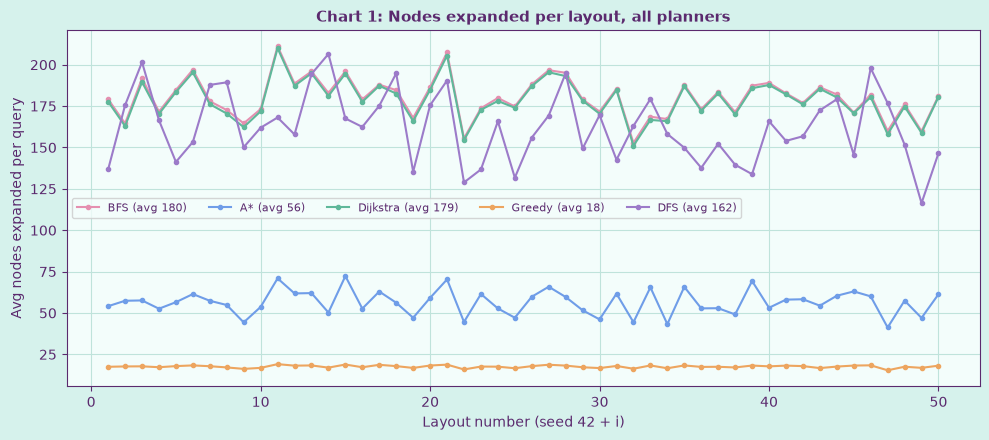

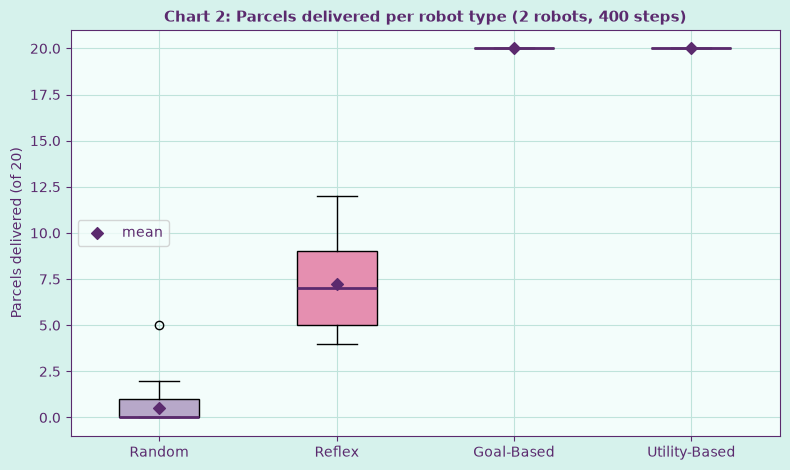

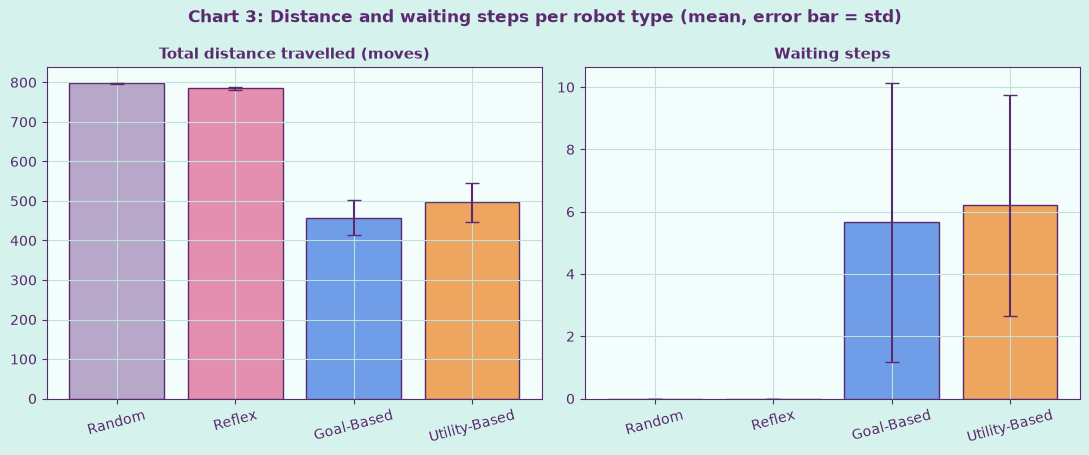

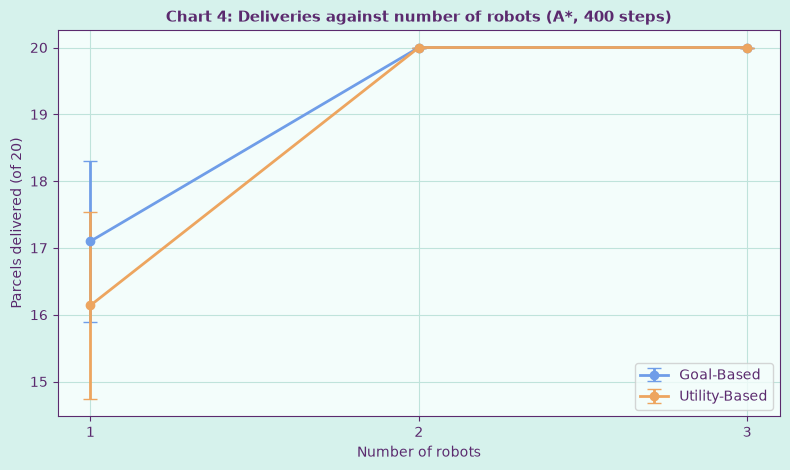

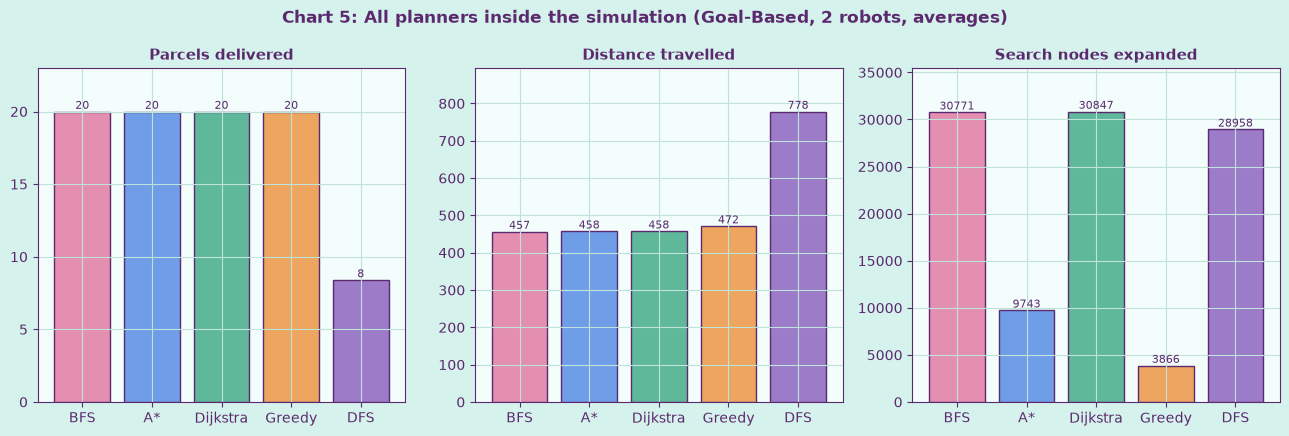

In [13]:
# CELL 11 | EXPERIMENT CHARTS: charts of the experiment results (displayed only, nothing is saved)
plot_all(RESULTS)